# Adel, 5: experimental data

**What you will learn:** describe a plant from measured dimensions, give the model a measured temperature, compare its
outputs with observations, measure the difference, and adjust (fit) a parameter so that the model matches the
observations.

**You need:** tutorials 1 and 2, and a little pandas. **Run time:** about 20 seconds.

**About the data.**
- The measured dimensions are real data shipped with Adel: the leaves, sheaths and internodes of a wheat main stem,
  given as the example input of Adel's plantgen tool (`Mariem_dimT_user_MIN.csv`).
- The temperature and the observations in `data/` are **synthetic**: `data/make_synthetic_data.py` made them from the
  model itself, with a phyllochron of 100 °Cd and some random noise. They stand for what an experiment gives. Since the
  true value is known, we can check that the fit finds it. Your own measurements go in files of the same form.

## 1. A plant from measured dimensions

The measurements give, for each phytomer of the main stem from the bottom, the length and width of its blade, sheath
and internode, in cm. These are the column names of Adel's plantgen tool:

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.adel.simulation import simulate, tables_from_measurements
from openalea.adel.tables import DATA

dimensions = pd.read_csv(os.path.join(DATA, "Mariem_dimT_user_MIN.csv"))
dimensions

,index_phytomer,L_blade,W_blade,L_sheath,W_sheath,L_internode,W_internode
0,1,9.446,0.380,2.843,0.158,0.000,0.000
1,2,9.267,0.374,2.931,0.183,0.000,0.000
2,3,8.029,0.445,3.244,0.209,0.000,0.000
3,4,9.665,0.579,3.894,0.234,0.000,0.000
4,5,11.260,0.750,4.482,0.259,0.000,0.000
5,6,12.328,0.986,6.813,0.284,0.000,0.000
6,7,14.073,1.020,8.892,0.310,1.553,0.000
7,8,17.253,1.060,9.580,0.335,4.447,0.064
8,9,17.747,1.080,10.117,0.360,6.427,0.134
9,10,16.264,1.100,11.073,0.386,11.300,0.192


`tables_from_measurements` turns them into the two tables Adel reads (one row per axis, one row per phytomer). The
tillers take the main stem's dimensions times 0.9, as in Adel. The tables are given to `simulate` as parameters:

In [2]:
measured_plant = tables_from_measurements(dimensions)
measured_plant["phytomer_table"].head()

,plant,axe,n,Ll,Lw,Gl,Gd,El,Ed,Azim,Lindex,Lseed
0,1,MS,1,9.446,0.380,2.843,0.158,0.0,0.0,180.0,6.0,1.0
1,1,MS,2,9.267,0.374,2.931,0.183,0.0,0.0,180.0,6.0,1.0
2,1,MS,3,8.029,0.445,3.244,0.209,0.0,0.0,180.0,6.0,1.0
3,1,MS,4,9.665,0.579,3.894,0.234,0.0,0.0,180.0,6.0,1.0
4,1,MS,5,11.260,0.750,4.482,0.259,0.0,0.0,180.0,6.0,1.0


If your measurements are in other units, convert them to cm (Adel's tables' unit) before.

## 2. A measured input: the temperature

The data give the daily mean air temperature, warming from about 8 to 16 °C. `simulate` takes it as a pandas Series
indexed by day:

,day,haun_stage,green_leaf_area,height
0,10,1.09,1.4,0.0
1,20,1.65,3.5,0.0
2,30,2.62,7.1,1.1
3,40,3.89,12.9,2.8
4,50,5.34,26.0,3.0
5,60,6.47,36.5,3.9
6,70,7.75,55.0,4.7
7,80,9.15,78.0,8.8
8,90,10.70,67.7,13.0


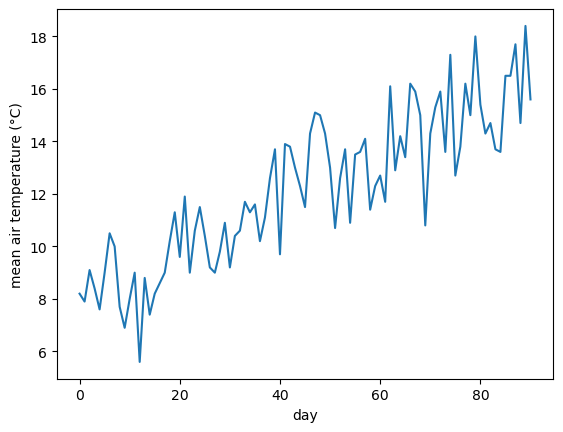

In [3]:
temperature = pd.read_csv("data/air_temperature.csv").set_index("day")["temperature"]
observed = pd.read_csv("data/observed_development.csv")
plt.plot(temperature.index, temperature.values)
plt.xlabel("day"); plt.ylabel("mean air temperature (°C)")
observed

The observations, every 10 days: the main stem's Haun stage, the plant's green leaf area (cm²) and its height (cm).

## 3. Compare with the observations

The plant with its measured dimensions, at the measured temperature, with the default phyllochron:

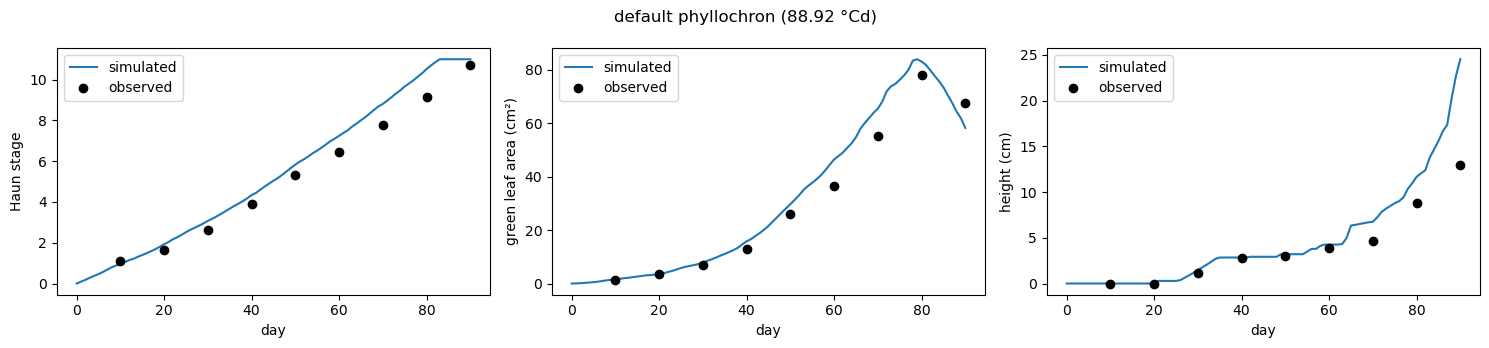

In [4]:
DAYS = 90


def compare(result, title):
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
    for ax, column, factor, label in ((axes[0], "haun_stage", 1, "Haun stage"),
                                      (axes[1], "green_leaf_area", 1e4, "green leaf area (cm²)"),
                                      (axes[2], "height", 100, "height (cm)")):
        ax.plot(result.summary["day"], result.summary[column] * factor, label="simulated")
        ax.plot(observed["day"], observed[column], "o", color="k", label="observed")
        ax.set_xlabel("day"); ax.set_ylabel(label); ax.legend()
    fig.suptitle(title)
    plt.tight_layout()


with_default = simulate(measured_plant, days=DAYS, temperature=temperature)
compare(with_default, "default phyllochron (88.92 °Cd)")

The simulated leaves appear too early. A single number measures the difference: the **root mean square error**
(RMSE) between the simulated and observed Haun stages, in leaves.

In [5]:
def rmse(result, column="haun_stage", factor=1.):
    simulated = np.interp(observed["day"], result.summary["day"], result.summary[column] * factor)
    return float(np.sqrt(np.mean((simulated - observed[column]) ** 2)))


print(f"Haun stage: an error of {rmse(with_default):.2f} leaves with the default phyllochron")

Haun stage: an error of 0.70 leaves with the default phyllochron


## 4. Fit a parameter

The pace of leaf appearance is set by the phyllochron. Fitting it means finding the value that makes the error
smallest. `scipy.optimize.minimize_scalar` searches it between two bounds by running the model repeatedly:

In [6]:
from scipy.optimize import minimize_scalar


def error(phyllochron):
    return rmse(simulate(dict(measured_plant, phyllochron=phyllochron), days=DAYS, temperature=temperature))


fit = minimize_scalar(error, bounds=(60., 140.), method="bounded", options={"xatol": 0.1})
print(f"fitted phyllochron = {fit.x:.1f} °Cd after {fit.nfev} simulations; Haun stage error {fit.fun:.2f} leaves")
print("the value used to make the synthetic data: 100 °Cd")

fitted phyllochron = 101.1 °Cd after 8 simulations; Haun stage error 0.13 leaves
the value used to make the synthetic data: 100 °Cd


green leaf area: 6.2 cm² of error before the fit, 3.7 cm² after


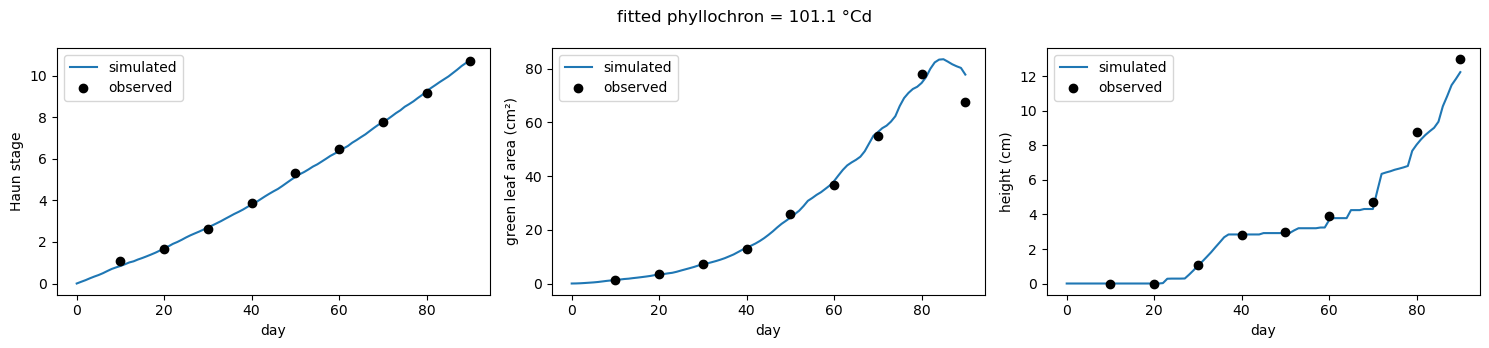

In [7]:
fitted = simulate(dict(measured_plant, phyllochron=fit.x), days=DAYS, temperature=temperature)
compare(fitted, f"fitted phyllochron = {fit.x:.1f} °Cd")
print(f"green leaf area: {rmse(with_default, 'green_leaf_area', 1e4):.1f} cm² of error before the fit, "
      f"{rmse(fitted, 'green_leaf_area', 1e4):.1f} cm² after")

The fitted value is close to the true one: the noise added to the Haun stages keeps it from being exact. The leaf
area, which was **not** used in the fit, is now closer to its observations too. This is a first check of the model: it
predicts an observation it was not fitted on.

With real data, you would fit on part of the observations and keep the others for this check, and you would fit the
parameters each observation depends on (tutorial 4 tells which).

## Try it yourself

1. Fit the phyllochron on the leaf area instead of the Haun stage (`rmse(result, "green_leaf_area", 1e4)`). Is the
   fitted value the same?
2. Simulate the measured plant at a constant 12 °C with the fitted phyllochron. How many days does it take to reach a
   Haun stage of 10?
3. Change one measured dimension (for example the flag leaf's `L_blade`) and see which outputs change.

**Next:** `06_with_other_models.ipynb`.